Clase IA

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

In [2]:
gray_scale = 255

x_train = x_train.astype('float32') / gray_scale
x_test = x_test.astype('float32') / gray_scale

print("Feature matrix (x_train):", x_train.shape)
print("Target matrix (y_train):", y_train.shape)
print("Feature matrix (x_test):", x_test.shape)
print("Target matrix (y_test):", y_test.shape)

Feature matrix (x_train): (60000, 28, 28)
Target matrix (y_train): (60000,)
Feature matrix (x_test): (10000, 28, 28)
Target matrix (y_test): (10000,)


In [3]:
gray_scale = 255

x_train = x_train.astype('float32') / gray_scale
x_test = x_test.astype('float32') / gray_scale

print("Feature matrix (x_train):", x_train.shape)
print("Target matrix (y_train):", y_train.shape)
print("Feature matrix (x_test):", x_test.shape)
print("Target matrix (y_test):", y_test.shape)

Feature matrix (x_train): (60000, 28, 28)
Target matrix (y_train): (60000,)
Feature matrix (x_test): (10000, 28, 28)
Target matrix (y_test): (10000,)


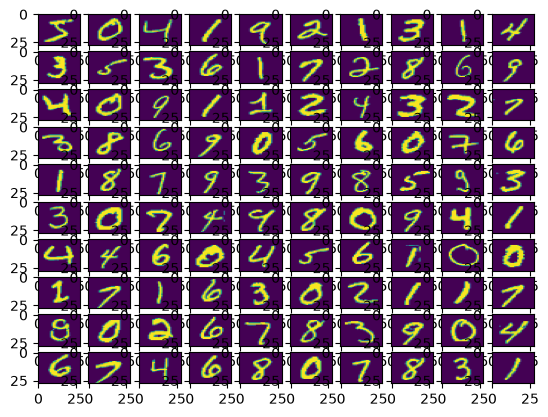

In [4]:
fig, ax = plt.subplots(10, 10)
k = 0
for i in range(10):
    for j in range(10):
        ax[i][j].imshow(x_train[k].reshape(28, 28), aspect='auto')
        k += 1
plt.show()

In [5]:
model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(256, activation='sigmoid'),
    Dense(128, activation='sigmoid'),
    Dense(10, activation='softmax'),
])

C:\Users\angel\PycharmProjects\PyCharmHome\.venv\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [6]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [17]:
mod = model.fit(x_train, y_train, epochs=10,
          batch_size=2000,
          validation_split=0.2)

print(mod)

Epoch 1/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.6419 - loss: 1.1775 - val_accuracy: 0.6728 - val_loss: 1.1355
Epoch 2/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.6550 - loss: 1.1326 - val_accuracy: 0.6864 - val_loss: 1.0910
Epoch 3/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.6680 - loss: 1.0910 - val_accuracy: 0.6971 - val_loss: 1.0496
Epoch 4/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.6796 - loss: 1.0525 - val_accuracy: 0.7099 - val_loss: 1.0112
Epoch 5/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.6890 - loss: 1.0171 - val_accuracy: 0.7204 - val_loss: 0.9760
Epoch 6/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.6985 - loss: 0.9846 - val_accuracy: 0.7299 - val_loss: 0.9441
Epoch 7/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.7078 - loss: 0.9547 - val_accuracy: 0.7373 - val_loss: 0.9154
Epoch 8/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.7163 - loss: 0.9272 - val_accuracy: 0.7432 - v

In [19]:
results = model.evaluate(x_test, y_test, verbose=0)
print('Test loss, Test accuracy:', results)

Test loss, Test accuracy: [0.850327730178833, 0.7450000047683716]


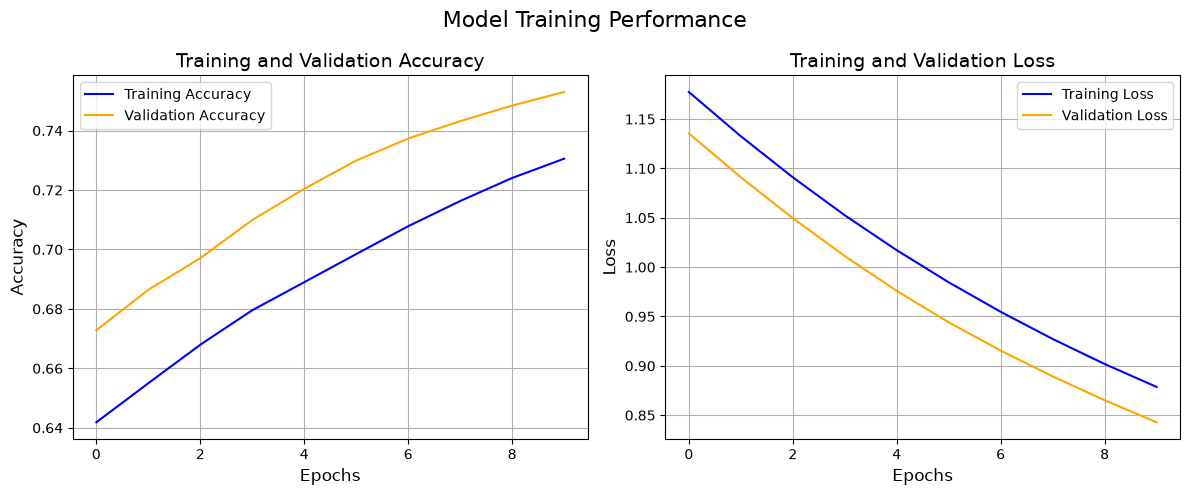

In [18]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(mod.history['accuracy'], label='Training Accuracy', color='blue')
plt.plot(mod.history['val_accuracy'],
         label='Validation Accuracy', color='orange')
plt.title('Training and Validation Accuracy', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(mod.history['loss'], label='Training Loss', color='blue')
plt.plot(mod.history['val_loss'], label='Validation Loss', color='orange')
plt.title('Training and Validation Loss', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend()
plt.grid(True)

plt.suptitle("Model Training Performance", fontsize=16)
plt.tight_layout()
plt.show()

In [20]:
import tkinter as tk
from PIL import Image, ImageDraw

def preparar(img):
    a = np.array(img)
    ys, xs = np.where(a > 0)
    img = img.crop((xs.min(), ys.min(), xs.max() + 1, ys.max() + 1))
    w, h = img.size
    k = 20 / max(w, h)
    img = img.resize((max(1, round(w * k)), max(1, round(h * k))))
    lienzo = Image.new('L', (28, 28), 0)
    lienzo.paste(img, ((28 - img.width) // 2, (28 - img.height) // 2))
    a = np.array(lienzo, dtype='float32') / 255
    cy = (a.sum(1) * np.arange(28)).sum() / a.sum()
    cx = (a.sum(0) * np.arange(28)).sum() / a.sum()
    return np.roll(a, (round(14 - cy), round(14 - cx)), axis=(0, 1))

root = tk.Tk()
root.title('Demo')
canvas = tk.Canvas(root, width=280, height=280, bg='black')
canvas.pack()
etiqueta = tk.Label(root, text='Dibuja un número', font=('Arial', 24))
etiqueta.pack()

img = Image.new('L', (280, 280), 0)
pincel = ImageDraw.Draw(img)
ultimo = [None]

def punto(x, y):
    canvas.create_oval(x - 9, y - 9, x + 9, y + 9, fill='white', outline='white')
    pincel.ellipse([x - 9, y - 9, x + 9, y + 9], fill=255)

def mover(e):
    if ultimo[0]:
        canvas.create_line(*ultimo[0], e.x, e.y, fill='white', width=18)
        pincel.line([*ultimo[0], e.x, e.y], fill=255, width=18)
    punto(e.x, e.y)
    ultimo[0] = (e.x, e.y)

def soltar(e):
    ultimo[0] = None
    p = model.predict(preparar(img)[None], verbose=0)[0]
    etiqueta.config(text=f'{p.argmax()} ({p.max() * 100:.0f}%)')

def borrar():
    canvas.delete('all')
    pincel.rectangle([0, 0, 280, 280], fill=0)
    etiqueta.config(text='Dibuja un número')

canvas.bind('<B1-Motion>', mover)
canvas.bind('<ButtonRelease-1>', soltar)
tk.Button(root, text='Borrar', command=borrar).pack()
root.mainloop()
